In [1]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import RelaxationTissueModel

microtorch_model = ModelMaker("SphereBallAstrosticks")
sphere, ball, astrosticks = microtorch_model.compartments

# Sphere's diffusivity is fixed inside the compartment, not a model parameter.
sphere.fixed_D = 2

# Make Astrosticks use a fixed D_par of 9.0.
astrosticks.fixed_D_par = 9.0
astrosticks.parameter_ranges = [[9.0, 9.0]]
microtorch_model.parameter_ranges[-1, :] = [9.0, 9.0]

model = MicrotorchTissueModel(
    microtorch_model,
    parameters={
        "radius": 6.0,  # Sphere radius
        "D": 2,        # Ball diffusivity
        "D_par": 9.0,    # Astrosticks parallel diffusivity
        "f_0": 0.6,      # Sphere
        "f_1": 0.3,      # Ball
        "f_2": 0.1,      # Astrosticks; derived from f_0 and f_1
    },
)

# Keep the Ball and Astrosticks diffusivities fixed during fitting.
for name in ("D", "D_par"):
    model[name].optimize = False
    model[name].fit_flag = False


model = RelaxationTissueModel(model, t2= 100e-3)
# model["T2"].optimize = False
# model["T2"].fit_flag = False
# #lmodel["T2"].scale = 1

# model["S0"].optimize = True
# model["S0"].fit_flag = True


model["model_radius"].value_list = [5, 10, 15]

model["model_f_0"].value_list = [0.5, 0.6, 0.7]
model["model_f_1"].value_list = [0.4, 0.3, 0.2]

model["T2"].optimize = False
model["T2"].fit_flag = False
print("Sphere fixed diffusivity:", sphere.fixed_D)
print(model)

No YAML configuration found for SphereBallAstrosticks model.
Falling back to parsing model name for compartments: ['Sphere', 'Ball', 'Astrosticks'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  SphereBallAstrosticks
########### Compartments: ['Sphere', 'Ball', 'Astrosticks']
########### Parameter names: [['radius'], ['D'], ['D_par']]
########### Parameter ranges: [[[0.001, 15]], [[0.001, 3]], [[0.5, 3.0]]]
-----------
Sphere fixed diffusivity: 2
Tissue model with 8 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_radius            6      1      True        True   (0.001, 15.0)
model_D                 2      1      False       False  (0.001, 3.0)
model_D_par             9      1      False       False  (9.0, 9.0)
model_f_0               0.6    1      True        True   (0.0, 1.0)
model_f_1               0.3    1      True  

In [2]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 5
block_size = n_directions + 1  # b0 + n_directions

# shell_bvals = [1500, 1000, 2200, 2500, 2500]
# shell_deltas = [0.0258, 0.0205,0.0205,0.0334, 0.0334]
# shell_Deltas = [0.0434, 0.0431,0.0431, 0.0455, 0.0455]
# initial_te = 0.09


shell_bvals = [2999, 2000, 1500, 500, 90]
shell_deltas = [0.0247, 0.0132, 0.0247, 0.0122, 0.0122]
shell_Deltas = [0.0438, 0.0323, 0.0434, 0.0313, 0.0238]
initial_te = [0.090, 0.067, 0.090, 0.065, 0.050]
# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# One optimized TE, delta, and Delta per shell, shared across that shell's
# b0 and diffusion-weighted measurements.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Keep each b0 gradient magnitude fixed at zero.
# All diffusion-weighted gradient magnitudes remain independently optimizable.
b0_mask = np.isclose(b_vals, 0.0)
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)

magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

# Check the masks and b0 values.
print("Timing free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Gradient-magnitude free indices:",
      np.flatnonzero(magnitude.optimize_mask))
print("b0 gradient magnitudes:", magnitude.values[b0_mask])

assert np.all(magnitude.values[b0_mask] == 0.0)
assert not np.any(magnitude.optimize_mask[b0_mask])

print(magnitude.optimize_mask)
print(initial_scheme)


Timing free indices: [ 0  7 14 21 28]
Gradient-magnitude free indices: [ 1  8 15 22 29]
b0 gradient magnitudes: [-0. -0. -0. -0. -0.]
[False  True False False False False False False  True False False False
 False False False  True False False False False False False  True False
 False False False False False  True False False False False False]
Acquisition scheme with 35 measurements and 6 scalar parameters. 
total number of optimized parameters is 20:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 660)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-----------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                            

In [3]:
jacobian = model.scaled_jacobian(initial_scheme)
print(jacobian)
print(jacobian.shape)


signal = model(initial_scheme)
print(signal)

[[ 0.          0.          0.        ]
 [-0.02075986  0.27427635 -0.06834403]
 [-0.02075986  0.27427635 -0.06834403]
 [-0.02075986  0.27427635 -0.06834403]
 [-0.02075986  0.27427635 -0.06834403]
 [-0.02075986  0.27427635 -0.06834403]
 [-0.02075986  0.27427635 -0.06834403]
 [ 0.          0.          0.        ]
 [-0.02965561  0.30198982 -0.09751633]
 [-0.02965561  0.30198982 -0.09751633]
 [-0.02965561  0.30198982 -0.09751633]
 [-0.02965561  0.30198982 -0.09751633]
 [-0.02965561  0.30198982 -0.09751633]
 [-0.02965561  0.30198982 -0.09751633]
 [ 0.          0.          0.        ]
 [-0.01140742  0.27534803 -0.07782285]
 [-0.01140742  0.27534803 -0.07782285]
 [-0.01140742  0.27534803 -0.07782285]
 [-0.01140742  0.27534803 -0.07782285]
 [-0.01140742  0.27534803 -0.07782285]
 [-0.01140742  0.27534803 -0.07782285]
 [ 0.          0.          0.        ]
 [-0.00942538  0.27398885 -0.02545707]
 [-0.00942538  0.27398885 -0.02545707]
 [-0.00942538  0.27398885 -0.02545707]
 [-0.00942538  0.27398885

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [4]:
# import microtool.optimize.methods as methods
# from microtool.optimize import optimize_scheme

# optimal_scheme, _ = optimize_scheme(initial_scheme, model, noise_variance=0.02, method="trust-constr", solver_options = {
#     "verbose": 2,
#     "maxiter": 300,
#     #"finite_diff_rel_step": 1e-8,  # Prevents large jumps during gradient estimation
#     #"initial_tr_radius": 0.05        # Prevents trust radius from jumping to 35.0
# })

In [5]:
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme

import numpy as np
from microtool.optimize.loss_functions import compute_loss, gauss_loss



method = methods.SOMA()
optimal_scheme, _ = optimize_scheme(
    initial_scheme, model, noise_variance=0.02, method=method
)

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/tissue_model.py:722: UserWarning: If T2 relaxation is not used for fitting, echo time should be fixed.
  warnings.warn("If T2 relaxation is not used for fitting, echo time should be fixed.")


[SOMA] Starting Optimization
  Dimension (Nx)     : 20
  Population Size    : 50
  Max Migrations     : 200
  Max Fevals         : 200000
  Jumps per movement : 28
[Init] hit-and-run from x0 | Nx=20, target=50, burn_in=2000, thin=100, n_active=None
[Init]   2/50 | step=2100 | segment (rel)=3.700e-05 | dist from x0 (rel)=4.856e-03
[Init]   3/50 | step=2200 | segment (rel)=1.127e-03 | dist from x0 (rel)=4.925e-03
[Init]   4/50 | step=2300 | segment (rel)=1.370e-04 | dist from x0 (rel)=4.947e-03
[Init]   5/50 | step=2400 | segment (rel)=5.866e-04 | dist from x0 (rel)=4.926e-03
[Init]   6/50 | step=2500 | segment (rel)=1.235e-04 | dist from x0 (rel)=5.231e-03
[Init]   7/50 | step=2600 | segment (rel)=6.471e-05 | dist from x0 (rel)=5.514e-03
[Init]   8/50 | step=2700 | segment (rel)=4.129e-04 | dist from x0 (rel)=5.322e-03
[Init]   9/50 | step=2800 | segment (rel)=6.017e-06 | dist from x0 (rel)=5.153e-03
[Init]  10/50 | step=2900 | segment (rel)=2.453e-04 | dist from x0 (rel)=5.038e-03
[Ini

In [6]:
import numpy as np
import pandas as pd


def get_unique_shells(scheme, scheme_name="Scheme"):
    df = pd.DataFrame(
        {
            "Scheme": scheme_name,
            "b_value": np.round(scheme.b_values, 1),
            "TE_ms": np.round(scheme.echo_times * 1e3, 2),
            "delta_ms": np.round(scheme.pulse_durations * 1e3, 2),
            "Delta_ms": np.round(scheme.pulse_intervals * 1e3, 2),
        }
    )

    # Filter out b = 0
    df_nonzero = df[df["b_value"] > 0]

    # Group by unique parameters and count directions
    shells = (
        df_nonzero.groupby(
            ["Scheme", "b_value", "TE_ms", "delta_ms", "Delta_ms"], as_index=False
        )
        .size()
        .rename(columns={"size": "N_directions"})
    )
    return shells


# Combine initial and optimal shells
shells_initial = get_unique_shells(initial_scheme, scheme_name="Initial")
shells_optimal = get_unique_shells(optimal_scheme, scheme_name="Optimal")

combined_shells = pd.concat([shells_initial, shells_optimal], ignore_index=True)

print(combined_shells.to_string(index=False))

 Scheme  b_value  TE_ms  delta_ms  Delta_ms  N_directions
Initial     90.0  50.00     12.20     23.80             6
Initial    500.0  65.00     12.20     31.30             6
Initial   1500.0  90.00     24.70     43.40             6
Initial   2000.0  67.00     13.20     32.30             6
Initial   2999.0  90.00     24.70     43.80             6
Optimal    130.4  39.43     14.07     21.35             6
Optimal    666.7  67.13     10.00     53.13             6
Optimal   2925.9  74.72     24.20     46.52             6
Optimal   3000.0  30.78     10.00     16.78             6
Optimal   3000.0  83.84     36.51     43.33             6


In [7]:
from pathlib import Path
import pickle
from microtool.monte_carlo.IO import make_expirement_directories

# Pass parent directory as cwd / "Ball_T2", experiment as "Shell_3"
plotdir, modeldir, simdir, schemedir = make_expirement_directories(
    Path.cwd() / "VERDICT", "Test_SOMA_t2_check"
)
print(schemedir)

# Save schemes and model
with open(schemedir / "initial_scheme.pkl", "wb") as f:
  pickle.dump(initial_scheme, f)

with open(schemedir / "optimal_scheme.pkl", "wb") as f:
  pickle.dump(optimal_scheme, f)

with open(modeldir / "model.pkl", "wb") as f:
  pickle.dump(model, f)

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/VERDICT/Test_SOMA_t2_check/schemes


/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/monte_carlo/IO.py:38: UserWarning: There is already a folder with the name of the experiment. No new folders have been created.
  warnings.warn("There is already a folder with the name of the experiment. No new folders have been created.")


In [16]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats
import matplotlib.pyplot as plt


noise_distribution = stats.norm(0, scale=0.02)
model["model_radius"].value = 5
model["model_f_0"].value = 0.4
model["model_f_1"].value = 0.5



# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result
simulation.save(simdir / "initial.pkl")

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
optimal = simulation.result
simulation.save(simdir / "optimal.pkl")

Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:10<00:00, 98.29it/s]


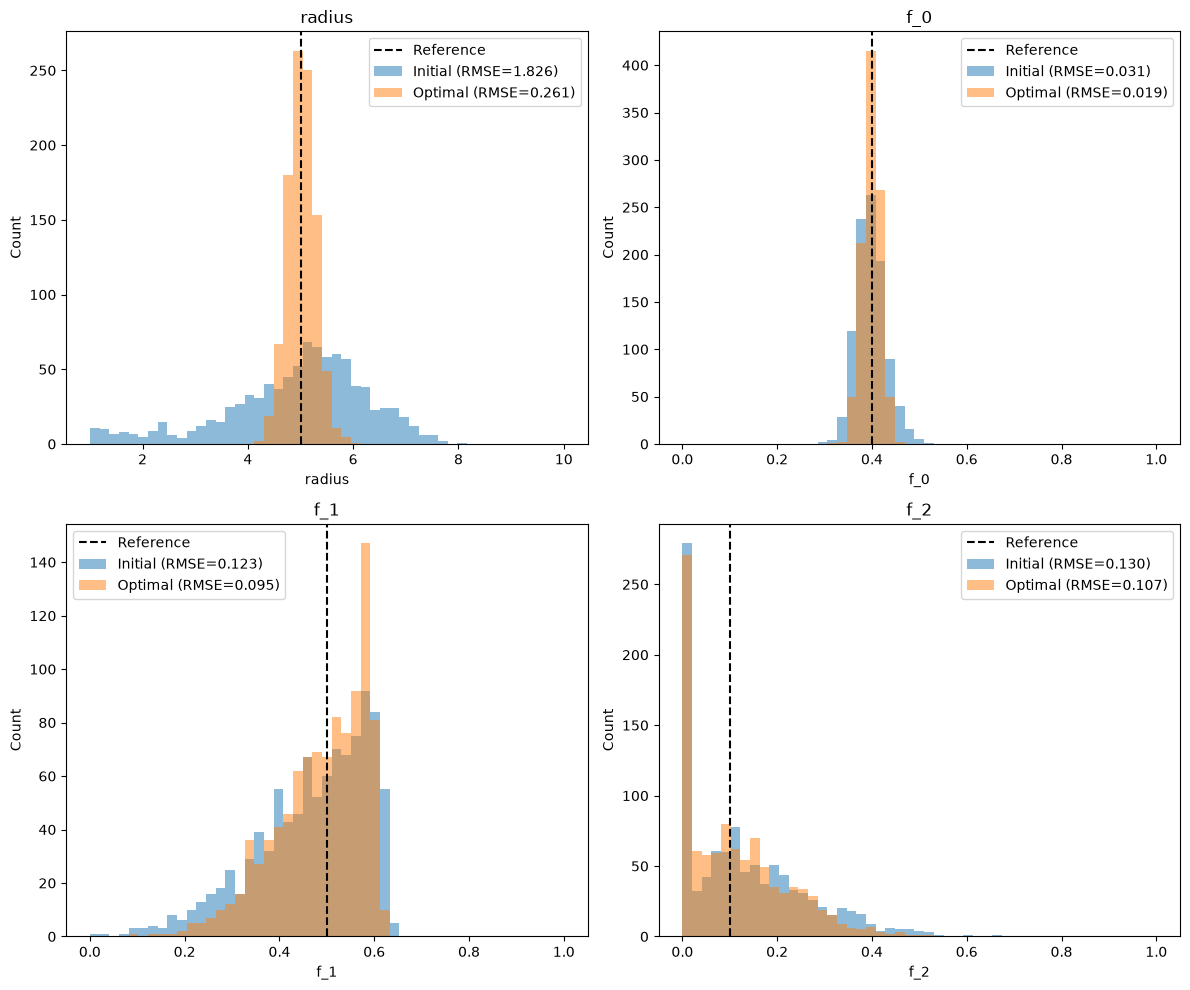

In [17]:
import numpy as np
from matplotlib import pyplot as plt

initial_result = initial
optimal_result = optimal

# 1. Compute derived fraction f_2 = 1 - f_0 - f_1 from simulation DataFrames
initial_f2 = 1 - initial_result["f_0"] - initial_result["f_1"]
optimal_f2 = 1 - optimal_result["f_0"] - optimal_result["f_1"]

# 2. Extract ground-truth reference values from model
radius_ref = model["model_radius"].value if "model_radius" in model else model["radius"].value
f0_ref = model["model_f_0"].value if "model_f_0" in model else model["f_0"].value
f1_ref = model["model_f_1"].value if "model_f_1" in model else model["f_1"].value
f2_ref = 1.0 - f0_ref - f1_ref

# Handle whether radius column in DataFrame is prefixed or not
radius_col = "radius" if "radius" in initial_result.columns else "model_radius"

plots_data = [
    (
        "radius",
        radius_ref,
        initial_result[radius_col],
        optimal_result[radius_col],
        np.linspace(0.2 * radius_ref, 2 * radius_ref, 50),
    ),
    (
        "f_0",
        f0_ref,
        initial_result["f_0"],
        optimal_result["f_0"],
        np.linspace(0, 1, 50),
    ),
    (
        "f_1",
        f1_ref,
        initial_result["f_1"],
        optimal_result["f_1"],
        np.linspace(0, 1, 50),
    ),
    (
        "f_2",
        f2_ref,
        initial_f2,
        optimal_f2,
        np.linspace(0, 1, 50),
    ),
]

# 3. Create 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, ref, init_vals, opt_vals, bins) in zip(axes, plots_data):
    init_rmse = np.sqrt(np.mean((init_vals - ref) ** 2))
    opt_rmse = np.sqrt(np.mean((opt_vals - ref) ** 2))

    ax.axvline(ref, color="black", linestyle="--", label="Reference")
    ax.hist(
        init_vals,
        bins=bins,
        alpha=0.5,
        label=f"Initial (RMSE={init_rmse:.3f})",
    )
    ax.hist(
        opt_vals,
        bins=bins,
        alpha=0.5,
        label=f"Optimal (RMSE={opt_rmse:.3f})",
    )

    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("Count")
    ax.legend()

plt.tight_layout()
plt.show()